# 8 Снижение размерности. Метод главных компонент. Анализ незавизимых компонент

**Цель работы:** с использованием различных методов и средств языка программирования Python снизить размерность входного датасета, избежав пропусков, с целью упрощения модели и ускорения последующего обучения.

**Выполнил:** ст.группы 24ВВИ1 Будников А.С.

## Теоретическая часть

### 1. Что понимается под снижением размерности данных и зачем этот этап используется в задачах прикладного искусственного интеллекта?

Снижение размерности данных - это процесс, или набор техник преобразования данных, направленных на уменьшение числа переменных путем выявления наиболее значащих переменных в наборе. Исходное многомерное пространство признаков на этом этапе процецируется в пространство с меньшей размерностью, чтобы в новом уменьшенном пространстве сохранилась наибольшее колчичество полезной информации о наборе данных. В задачах прикладного искуственного интеллекта используется в первую очередь во избежание проклятия размерности, при котором для текущего набора признаков для эффективного обучения требуется в разы больше наблюдений. Это не единственная причина. К целям этапа можно отнести снижение вычислительной сложности за счет сокращения объема входных данных, а также борьбу с шумом и случайными корреляциями и улучшение интерпретируемости.

### 2. В чём принципиальная идея метода главных компонент (PCA)?

Принципиальная идея метода главных компонент состоит в том, чтобы "повернуть" текущее многомерное пространство таким образом, что дисперсия при такой проекции будет максимальна. Оси строятся последовательно, перпендикулярно друг другу. Условно говоря мы растягиваем облако точек таким образом, чтобы оно занимало наибольшую площадь. Это позволяет отбросить компоненты с малой дисперсией вдоль осей, то есть те, которые несут малые объемы информации, и оставить только те, которые дают максимальное представление о структуре данных и их внутренним зависимостям.

### 3. Что означает дисперсия признаков и почему она важна для PCA?

Дисперсия признаков - это статистический параметр, отражающий мера разброса значений призака относительно его среднего. Измеряется в квадрате и показывает насколько значения варьируются относительно среднего. В контексте PCA дисперсия играет роль мерой сравнения - направлением, вдоль которого данные имеют наибольший разброс, а следственно являются более информативными. Метод как раз ищет ортогональные оси, которые максимизируют дисперсию проекций. Однако здесь стоит упомянуть, что большая дисперсия не всегда является синонимом информативности, что является важным ограничением метода.

### 4. Чем анализ независимых компонент (ICA) отличается от PCA по цели и результату?

И ICA, и PCA ищут линейное преобразование данных, однако имеют различней цели и задачи, что приводит к разным результатам. PCA стремится максимизировать дисперсию признаков при условии ортогональности найденных компонент. ICA стремится максимизировать независимость компонент, то есть построить построить такое пространство, в котором значение одной компоненты никак не влияет на значение другой, требование ортогональности при этом не ставится. Анализ независимых компонент не определяет порядок и важность сигналов. Это означает, что PCA выдает в результате сжатое представление данных, сохраняющее максимальную дисперсию, а ICA - разложение наблюдений на независимые источники.

### 5. Почему методы PCA и ICA применяются после масштабирования данных, а не до него?

Оба метода чувствительны к масштабу признаков, потому что их критерий зависит от величины разброса признака. PCA ищет направления максимальной дисперсии признаков, то есть при существенном различии в масштабе более "крупный" признак будет доминировать над другим из за единиц измерения (иметь большую дисперсию). Например, без стандартизации признак "Высота над уровнем моря", имеющий наибольшую дисперсию затмевал бы остальные, которые возможно затерялись бы в процессе выделения признаков...

## Практическая часть

## 2.1 Базовый уровень

In [1]:
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA, FastICA
from sklearn.manifold import TSNE

import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv('data/covtype-7-ss.csv')
test = pd.read_csv('data/covtype-7-test-ss.csv')

print(f'Train shape={train.shape}')
print(f'Test shape={test.shape}')

X_train = train.drop(columns=['Тип_лесного_покрова'])
y_train = train['Тип_лесного_покрова']
X_test = test.drop(columns=['Тип_лесного_покрова'])
y_test = test['Тип_лесного_покрова']

print(f'X_train={X_train.shape}\ty_train={y_train.shape}')
print(f'X_test={X_test.shape}\ty_test={y_test.shape}')

Train shape=(317254, 48)
Test shape=(116194, 48)
X_train=(317254, 47)	y_train=(317254,)
X_test=(116194, 47)	y_test=(116194,)


In [4]:
numeric = [col for col in X_train.columns if X_train[col].dtype == float]
binary = [col for col in X_train.columns if X_train[col].dtype == int]
print(f'numeric={numeric}')
print(f'categorical={binary}')
X_train_num = X_train[numeric]
X_test_num = X_test[numeric]

numeric=['Высота_над_уровнем_моря', 'Освещённость_3_дня', 'Освещённость_9_утра']
categorical=['Зона_дикой_природы_1', 'Зона_дикой_природы_2', 'Зона_дикой_природы_3', 'Зона_дикой_природы_4', 'Тип_почвы_1', 'Тип_почвы_2', 'Тип_почвы_3', 'Тип_почвы_4', 'Тип_почвы_5', 'Тип_почвы_6', 'Тип_почвы_7', 'Тип_почвы_8', 'Тип_почвы_9', 'Тип_почвы_10', 'Тип_почвы_11', 'Тип_почвы_12', 'Тип_почвы_13', 'Тип_почвы_14', 'Тип_почвы_15', 'Тип_почвы_16', 'Тип_почвы_17', 'Тип_почвы_18', 'Тип_почвы_19', 'Тип_почвы_20', 'Тип_почвы_21', 'Тип_почвы_22', 'Тип_почвы_23', 'Тип_почвы_24', 'Тип_почвы_25', 'Тип_почвы_26', 'Тип_почвы_27', 'Тип_почвы_28', 'Тип_почвы_29', 'Тип_почвы_30', 'Тип_почвы_31', 'Тип_почвы_32', 'Тип_почвы_33', 'Тип_почвы_34', 'Тип_почвы_35', 'Тип_почвы_36', 'Тип_почвы_37', 'Тип_почвы_38', 'Тип_почвы_39', 'Тип_почвы_40']


## Анализ

В качестве датасета используется [Forest Cover Types](https://www.kaggle.com/datasets/uciml/forest-cover-type-dataset/data).
Здесь содержатся данные о типах лесного покрова для территорий национального парка Рузвельта в Колорадо США. Каждая строка таблицы описывает один участок земли площадью 30×30 метров. Набор признаков включает информацию о типе дерева, степени затенения, расстоянии до близлежащих ориентиров (дорог и т. д.), типе почвы и местном рельефе.

Всего в датасете 581 012 записей и 55 столбцов, однако после очистки количество строк сократилось до 580 966. Для удобства чтения столбцы были переименованы.

Расшифрока значений целевой переменной:

1. Ель/Пихра
2. Сосна скрученная
3. Сосна пондероза
4. Тополь/Ива
5. Осина
6. Дугласова пихта
7. Круммхольц

На текущем этапе датасет уже прошел этапы очистки, масштабирования и отбора признаков в работах 5,6 и 7 соответственно, а также сэмплинг. Отмечу, что с самого начала данные делим на обучающую, или тренировочную, и тестовую выборки.

В информационной среде споры вызывает применимость рассматриваемых методов для бинарных признаков. Мнения по этому вопросу сильно разнятся, поэтому было принято решение провести эксперименты как с полным набором исходных признаков, так и с выборкой, включающей в себя только непрерывные числовые признаки. Такой подход возможно позволит оценить влияние бинарных значений на комопненты, которые формируют PCA и ICA.

In [5]:
X_train.head()

,Высота_над_уровнем_моря,Зона_дикой_природы_1,Зона_дикой_природы_2,Зона_дикой_природы_3,Зона_дикой_природы_4,Освещённость_3_дня,Освещённость_9_утра,Тип_почвы_1,Тип_почвы_2,Тип_почвы_3,...,Тип_почвы_31,Тип_почвы_32,Тип_почвы_33,Тип_почвы_34,Тип_почвы_35,Тип_почвы_36,Тип_почвы_37,Тип_почвы_38,Тип_почвы_39,Тип_почвы_40
0,0.383828,0,1,0,0,0.769626,-0.789638,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1.044453,1,0,0,0,-0.250597,-0.042156,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0.387399,1,0,0,0,0.560349,-0.154279,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.490956,0,0,1,0,-0.904587,0.406333,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,0.476672,1,0,0,0,-1.218502,0.854822,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
print('train types:')
print(X_train.dtypes)
print('\ntest types:')
print(X_test.dtypes)

train types:
Высота_над_уровнем_моря    float64
Зона_дикой_природы_1         int64
Зона_дикой_природы_2         int64
Зона_дикой_природы_3         int64
Зона_дикой_природы_4         int64
Освещённость_3_дня         float64
Освещённость_9_утра        float64
Тип_почвы_1                  int64
Тип_почвы_2                  int64
Тип_почвы_3                  int64
Тип_почвы_4                  int64
Тип_почвы_5                  int64
Тип_почвы_6                  int64
Тип_почвы_7                  int64
Тип_почвы_8                  int64
Тип_почвы_9                  int64
Тип_почвы_10                 int64
Тип_почвы_11                 int64
Тип_почвы_12                 int64
Тип_почвы_13                 int64
Тип_почвы_14                 int64
Тип_почвы_15                 int64
Тип_почвы_16                 int64
Тип_почвы_17                 int64
Тип_почвы_18                 int64
Тип_почвы_19                 int64
Тип_почвы_20                 int64
Тип_почвы_21                 int64
Тип_поч

## Анализ

Все признаки загрузились из файла с корректными, сформированными в прошлых работах работе типами данных `float64` и `int64`. При этом значения с плавающей точкой соответствуют непрерывным, а целочисленные - категориальным.

In [24]:
pca_full = PCA(random_state=42, n_components=2)
X_train_pca2 = pca_full.fit_transform(X_train)
X_test_pca2 = pca_full.transform(X_test)

cols = [f'C{i+1}' for i in range(X_train_pca2.shape[1])]

X_train_pca2 = pd.DataFrame(X_train_pca2, columns=cols, index=X_train.index)
X_test_pca2 = pd.DataFrame(X_test_pca2, columns=cols, index=X_test.index)

print(f'Prev: {X_train.shape[1]}\tNow: {X_train_pca2.shape[1]}')
print(f'Nan PCA: {np.isnan(X_train_pca2).sum()}')
print(f'Ratio:{pca_full.explained_variance_ratio_.sum()*100}')

Prev: 47	Now: 2
Nan PCA: C1    0
C2    0
dtype: int64
Ratio:75.45285768089933


In [25]:
X_train_pca2.sample(10)

,C1,C2
143919,2.188485,1.301794
256239,0.385555,1.639988
51591,0.894098,-1.538772
311845,3.148266,-0.856767
169018,-1.000424,-2.376305
159501,-2.582760,0.133593
229000,0.709691,-1.169197
176146,-1.479397,-1.454088
96633,-1.721359,0.454631
109683,-0.351504,-1.505068


## Анализ

Для полного набора данных выполнено снижение размерности с 47 изначальных столбцов до 2 компонент, чтобы построить гистограмму рассеяни как того требует задание. Преобразование обучено на обучающей и применено к обоим выборкам, что предотвращает утечку информации. Пропусков обнаружено не было. При этом две выделенные компоненты объясняют около 75% дисперсии исходного набора данных, то есть теряется примерно четверть полезной информации. Такое поведение весьма предсказуемо и будет рассмотрено позже.

In [32]:
pca_num = PCA(random_state=42, n_components=2)
X_train_pca2_num = pca2.fit_transform(X_train_num)
X_test_pca2_num = pca2.transform(X_test_num)

cols = [f'C{i+1}' for i in range(X_train_pca2_num.shape[1])]

X_train_pca2_num = pd.DataFrame(X_train_pca2_num, columns=cols, index=X_train.index)
X_test_pca2_num = pd.DataFrame(X_test_pca2_num, columns=cols, index=X_test.index)

print(f'Prev: {X_train_num.shape[1]}\tNow: {X_train_pca2_num.shape[1]}')
print(f'Nan PCA: {np.isnan(X_train_pca2_num).sum()}')
print(f'Ratio:{pca_num.explained_variance_ratio_.sum()*100}')
print(pca_num.explained_variance_ratio_)

Prev: 3	Now: 2
Nan PCA: C1    0
C2    0
dtype: int64
Ratio:94.48027825186432
[0.37939637 0.37513221]


## Анализ

В случае, когда в рассмотрение берутся только числовые признаки имеем обратную ситуацию. Две компоненты здесь объясняют почти 95% дисперсии, причем первая компонента здесь существенно отрывается по значимости. Это означает, что числовые признаки составляют основу, так как при сжатии осей теряется только около 5% полезной информации. Возможно бинарные признаки размывают структуру.

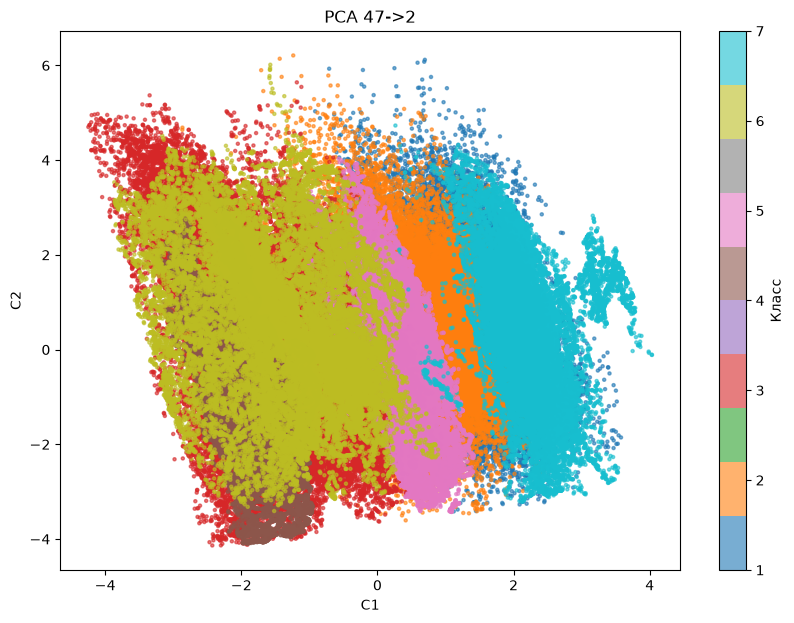

In [72]:
plt.figure(figsize=(10, 7))
sc = plt.scatter(X_train_pca2['C1'], X_train_pca2['C2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс')
plt.xlabel('C1'); plt.ylabel('C2')
plt.title('PCA 47->2')
plt.show()

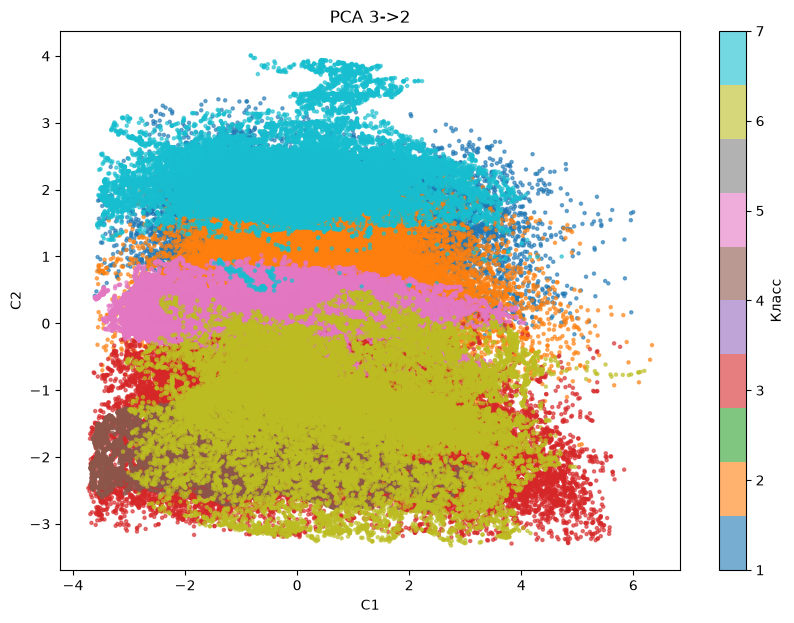

In [28]:
plt.figure(figsize=(10, 7))
sc = plt.scatter(X_train_pca2_num['C1'], X_train_pca2_num['C2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс')
plt.xlabel('C1'); plt.ylabel('C2')
plt.title('PCA 3->2')
plt.show()

## Анализ

На двух представленных диаграммах можем разглядеть визуально одно и то же облако в разных ориентациях осей. Объяснить это могу только тем, что в используемом наборе данных главными компонентами оказываются члены числовой выборки. То есть именно эти 3 признака вносят наибольшую дисперсию,, а следственно несут наибольшую информацию. В результате облако оказывается тем же, только повернутым. Облака имеют слоистую структуру, то есть состоит из нескольких "слоев", которые частично перекрывают друг друга. Возможно причиной всего этого является как раз наличие бинарных признаков, которые, во-первых, сильно коррелируют между собой, во-вторых, являются индикатором из-за стиля кодирования.

## 2.2. Анализ объяснённой дисперсии

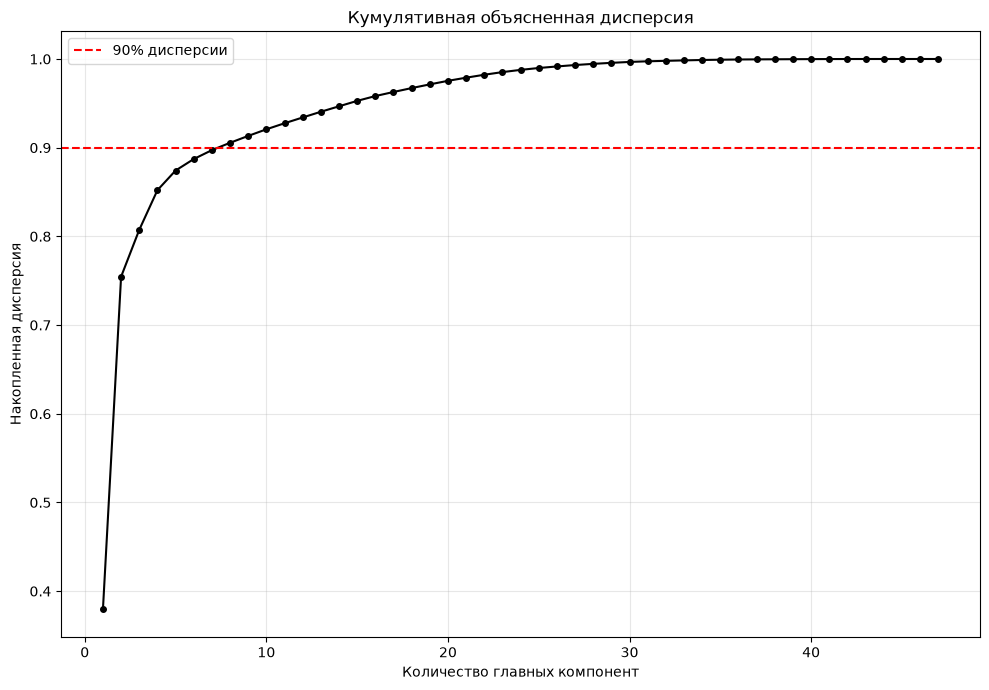

 n      Дисперсия, %
 1 37.93963677864151
 2 75.45285768089884
 5 87.42222635814426
 8 90.55170719411488
10 92.07242991047582
15 95.27798781746341


In [73]:
pca_A = PCA(random_state=42).fit(X_train)
cum_full = np.cumsum(pca_A.explained_variance_ratio_)
n_comp = len(cum_full)
n90_A = np.argmax(cum_A >= 0.9) + 1

if cum_full[-1] >= 0.9:
    full90 = int(np.argmax(cum_full >= 0.9) + 1)
else:
    full90 = n_comp  

plt.figure(figsize=(10, 7))
plt.plot(range(1, n_comp + 1), cum_full, marker='o', ms=4, color='k')
plt.axhline(0.9, color='r', ls='--', label='90% дисперсии')

plt.title('Кумулятивная объясненная дисперсия')
plt.xlabel('Количество главных компонент')
plt.ylabel('Накопленная дисперсия')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

n_values = sorted(list(set([n for n in [1, 2, 5, 10, full90, 15] if n <= n_comp])))

df_summary = pd.DataFrame({
    'n': n_values,
    'Дисперсия, %': [f'{cum_full[n-1]*100}' for n in n_values]
})
print(df_summary.to_string(index=False))

## Анализ

Для полного набора построена кривая накопленной объясненной дисперсии. По графику видно, что эта кривая плавно растет на первых 8-10 компонентах, а затем начинает выходить на плато. По результатам расчета видно, что для сохранения порогового значения в 90% необходимо только 8 компонент, а для 95% - 15. Это означает, что снижение размерности с 47 до 8 признаков сохраняет почти всю существенную информацию, а отбрасываемые компоненты, а остаточные несут в себе шум. Для этого случая разумным числом компонент будет от 10 до 15.

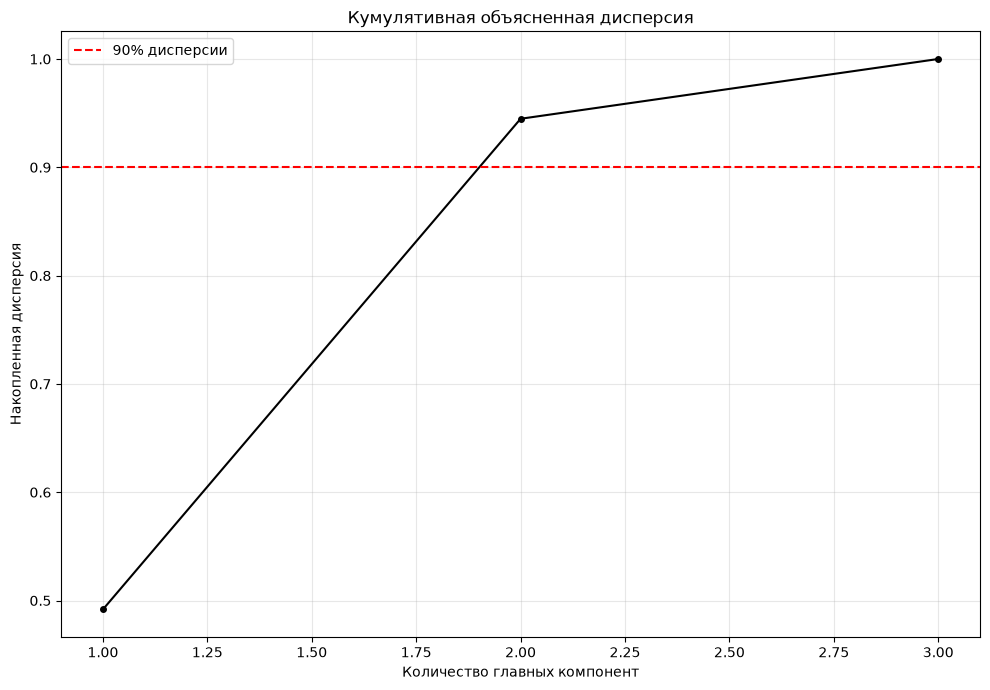

 n       Дисперсия, %
 1 49.178565243340486
 2  94.48027825186432
 3 100.00000000000003


In [53]:
pca_B = PCA(random_state=42).fit(X_train_num)
cum_B = np.cumsum(pca_B.explained_variance_ratio_)
n_comp = len(cum_B)
n90_B = np.argmax(cum_B >= 0.9) + 1

if cum_B[-1] >= 0.9:
    full90 = int(np.argmax(cum_B >= 0.9) + 1)
else:
    full90 = n_comp  

plt.figure(figsize=(10, 7))
plt.plot(range(1, n_comp + 1), cum_B, marker='o', ms=4, color='k')
plt.axhline(0.9, color='r', ls='--', label='90% дисперсии')

plt.title('Кумулятивная объясненная дисперсия')
plt.xlabel('Количество главных компонент')
plt.ylabel('Накопленная дисперсия')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

n_values = sorted(list(set([n for n in [1, 2, 3, full90] if n <= n_comp])))

df_summary = pd.DataFrame({
    'n': n_values,
    'Дисперсия, %': [f'{cum_B[n-1]*100}' for n in n_values]
})
print(df_summary.to_string(index=False))

## Анализ

Для второго случая с числовыми признаками ситуация другая. Здесь порог преодолевается уже при 2 компонентах, а третья добивает значение накопленной дисперсии до 100%. Это означает, что при снижении размерности с 3 до 2 осей практически не теряется полезная информация, однако при снижении до 1 оси теряется уже половина. Разумным числом компонент для этого случая можно сделать 2, так как это единственное число, которое при снижении размерности сохраняет неплохое количество дисперсии. Ниже диаграммы рассеяния по новым компонентам, повторяющие прошлые.

## Вопросы

1. Доля накопленной дисперсии с ростом числа компонент монотонно возрастает, но каждая последующая, как наблюдение, дает меньший прирост. Первые несколько компонент ловят основную структуру, а остальные могут быть отброшены.
2. Судя по методичке разумным можно считать число компонент, при котором объясняется 90-95% дисперсии. В моем случае для полного набора из 47 - 8 компонент, а для числового - 2. В обоих случаях наблюдается сокращение размерности при сохранении значительной доли полезной информации.

A | n90=8 | NaN: 0 | Ratio: 90.55%


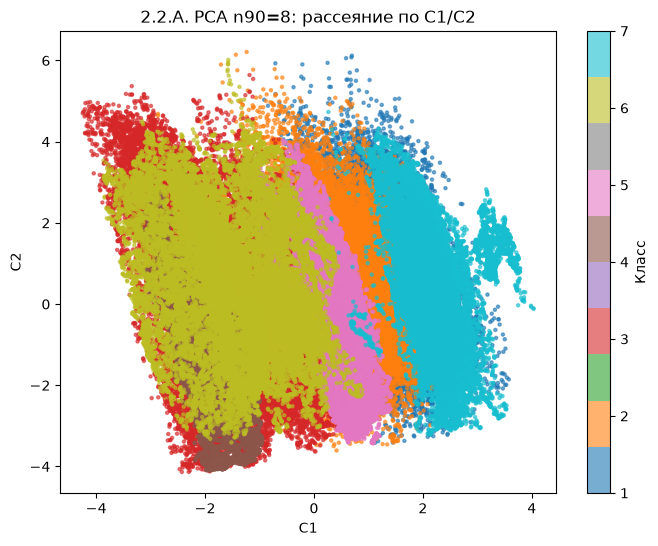

In [54]:
pca_A_n90 = PCA(n_components=n90_A, random_state=42)
X_train_pca_A_n90 = pca_A_n90.fit_transform(X_train)
X_test_pca_A_n90  = pca_A_n90.transform(X_test)

cols_n90 = [f'C{i+1}' for i in range(n90_A)]
X_train_pca_A_n90 = pd.DataFrame(X_train_pca_A_n90, columns=cols_n90, index=X_train.index)
X_test_pca_A_n90  = pd.DataFrame(X_test_pca_A_n90,  columns=cols_n90, index=X_test.index)

print(f'A | n90={n90_A} | NaN: {np.isnan(X_train_pca_A_n90).sum().sum()} | Ratio: {pca_A_n90.explained_variance_ratio_.sum()*100:.2f}%')

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_train_pca_A_n90['C1'], X_train_pca_A_n90['C2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс')
plt.xlabel('C1'); plt.ylabel('C2')
plt.title(f'2.2.A. PCA n90={n90_A}: рассеяние по C1/C2')
plt.show()

B | n90=2 | NaN: 0 | Ratio: 94.48%


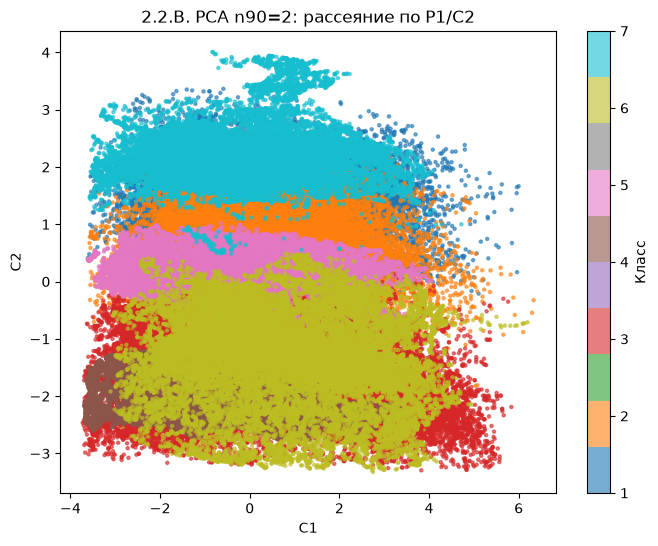

In [55]:
pca_B_n90 = PCA(n_components=n90_B, random_state=42)
X_train_pca_B_n90 = pca_B_n90.fit_transform(X_train_num)
X_test_pca_B_n90  = pca_B_n90.transform(X_test_num)

cols_n90B = [f'C{i+1}' for i in range(n90_B)]
X_train_pca_B_n90 = pd.DataFrame(X_train_pca_B_n90, columns=cols_n90B, index=X_train_num.index)
X_test_pca_B_n90  = pd.DataFrame(X_test_pca_B_n90,  columns=cols_n90B, index=X_test_num.index)

print(f'B | n90={n90_B} | NaN: {np.isnan(X_train_pca_B_n90).sum().sum()} | Ratio: {pca_B_n90.explained_variance_ratio_.sum()*100:.2f}%')

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_train_pca_B_n90['C1'], X_train_pca_B_n90['C2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс')
plt.xlabel('C1'); plt.ylabel('C2')
plt.title(f'2.2.B. PCA n90={n90_B}: рассеяние по P1/C2')
plt.show()

A | ICA: 5 комп. | NaN: 0 | итераций: 10


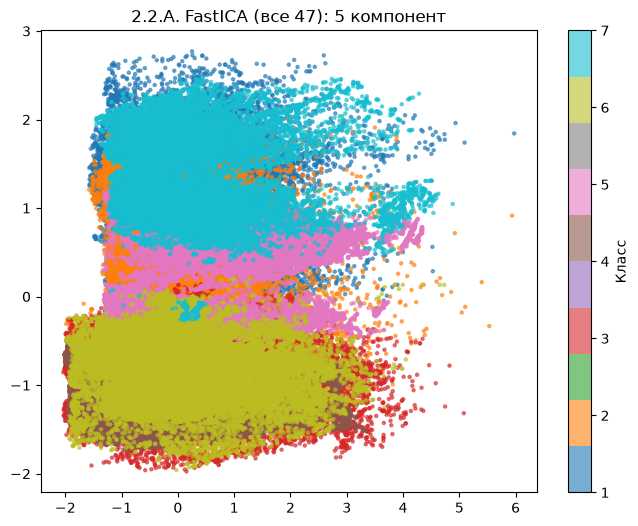

In [76]:
ica_a = FastICA(n_components=5, random_state=42)
X_train_ica_A = ica_a.fit_transform(X_train)
X_test_ica_A = ica_a.transform(X_test)

cols_ic = [f'IC{i+1}' for i in range(5)]
X_train_ica_A = pd.DataFrame(X_train_ica_A, columns=cols_ic, index=X_train.index)
X_test_ica_A  = pd.DataFrame(X_test_ica_A,  columns=cols_ic, index=X_test.index)

print(f'A | ICA: 5 комп. | NaN: {np.isnan(X_train_ica_A).sum().sum()} | итераций: {ica_a.n_iter_}')

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_train_ica_A['IC1'], X_train_ica_A['IC2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс'); plt.title('2.2.A. FastICA (все 47): 5 компонент'); plt.show()

A | ICA: 8 комп. | NaN: 0 | итераций: 10


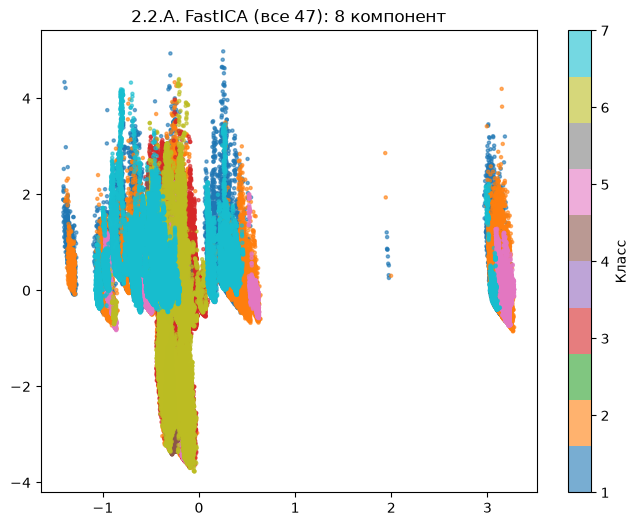

In [81]:
ica_a2 = FastICA(n_components=8, random_state=42)
X_train_ica_A2 = ica_a2.fit_transform(X_train)
X_test_ica_A2 = ica_a2.transform(X_test)

cols_ic = [f'IC{i+1}' for i in range(8)]
X_train_ica_A2 = pd.DataFrame(X_train_ica_A2, columns=cols_ic, index=X_train.index)
X_test_ica_A2  = pd.DataFrame(X_test_ica_A2,  columns=cols_ic, index=X_test.index)

print(f'A | ICA: 8 комп. | NaN: {np.isnan(X_train_ica_A2).sum().sum()} | итераций: {ica_a.n_iter_}')

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_train_ica_A2['IC1'], X_train_ica_A2['IC2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс'); plt.title('2.2.A. FastICA (все 47): 8 компонент'); plt.show()

## Анализ

Применен метод FastICA с 5 компонентами к полному набору. В отличие от PCA здесь компоненты неупорядоченны и облака имеют произвольные границы, разделение классов выражено слабее, хуже отделены друг от друга. Это можно объяснить тем, что ICA ищет независимые источники, а не направления максимального разброса. То есть для сжатия PCA вероятно подходит несколько больше. При этом при 8 компонентах, как было в PCA, график разрывается на несколько частей, точки в которых не поддаются объяснению.

B | ICA: 2 комп. | NaN: 0 | итераций: 3


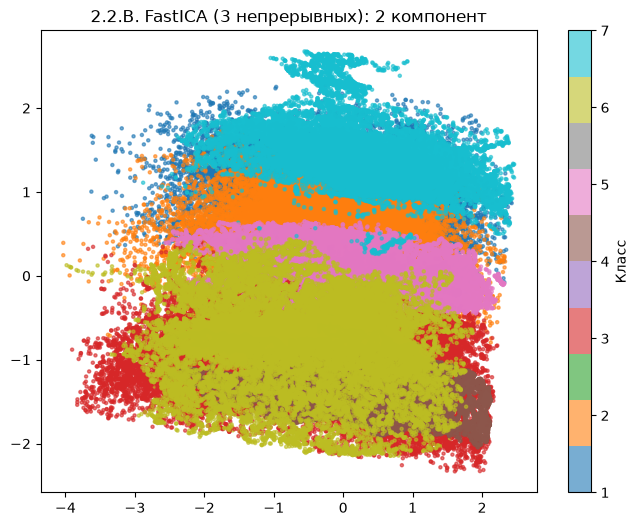

In [79]:
ica_b = FastICA(n_components=2, random_state=42)
X_train_ica_B = ica_b.fit_transform(X_train_num)
X_test_ica_B = ica_b.transform(X_test_num)

cols_ic = [f'IC{i+1}' for i in range(2)]
X_train_ica_B = pd.DataFrame(X_train_ica_B, columns=cols_ic, index=X_train_num.index)
X_test_ica_B  = pd.DataFrame(X_test_ica_B,  columns=cols_ic, index=X_test_num.index)

print(f'B | ICA: 2 комп. | NaN: {np.isnan(X_train_ica_B).sum().sum()} | итераций: {ica_b.n_iter_}')

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_train_ica_B['IC1'], X_train_ica_B['IC2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс'); plt.title('2.2.B. FastICA (3 непрерывных): 2 компонент'); plt.show()

B | ICA: 3 комп. | NaN: 0 | итераций: 3


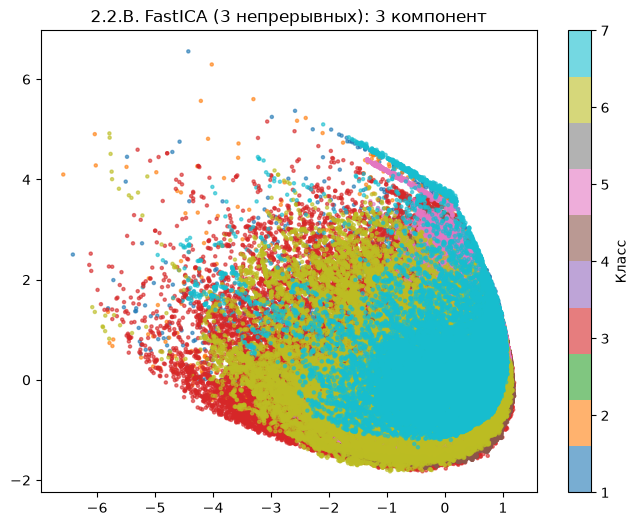

In [80]:
ica_b2 = FastICA(n_components=3, random_state=42)
X_train_ica_B2 = ica_b2.fit_transform(X_train_num)
X_test_ica_B2 = ica_b2.transform(X_test_num)

cols_ic = [f'IC{i+1}' for i in range(3)]
X_train_ica_B2 = pd.DataFrame(X_train_ica_B2, columns=cols_ic, index=X_train_num.index)
X_test_ica_B2  = pd.DataFrame(X_test_ica_B2,  columns=cols_ic, index=X_test_num.index)

print(f'B | ICA: 3 комп. | NaN: {np.isnan(X_train_ica_B).sum().sum()} | итераций: {ica_b.n_iter_}')

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_train_ica_B2['IC1'], X_train_ica_B2['IC2'], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Класс'); plt.title('2.2.B. FastICA (3 непрерывных): 3 компонент'); plt.show()

## Анализ

Здесь в отличие от PCA наблюдаем диаметрально противоположную картину. При смене выборки диаграмма рассеяния координально меняется. Здесь во втором случае наблюдается форма метеора или раковины c высокой плотностью точек справа. Здесь очевидно влияние отсутствия бинарных признаков в выборке. Здесь скорее всего наблюдается ситуация, при которой бинарные признаки добавляют в выборку большее отклонение от модели Гаусса, так как по своей природе далеки от нормального распеределения. А тот факт, что мы не понижаем размерность в одном их экспериментов, подсказывает, что в данном случае метод просто вытягивает все компоненты так, чтобы они были максимально независимы. В результате график превращается из слоистого в вытянутый.

## Вопросы

1. 5, или 8 для полного набора, 3, или 2 для числового.
2. Структура данных чем то похожа, при некоторых параметрах наблюдается та же структура, однако при изменении количества результирующиъ компонент график существенно меняется - разрывается или превращается в веер.

## 2.3. Контроль корректности подготовки данных

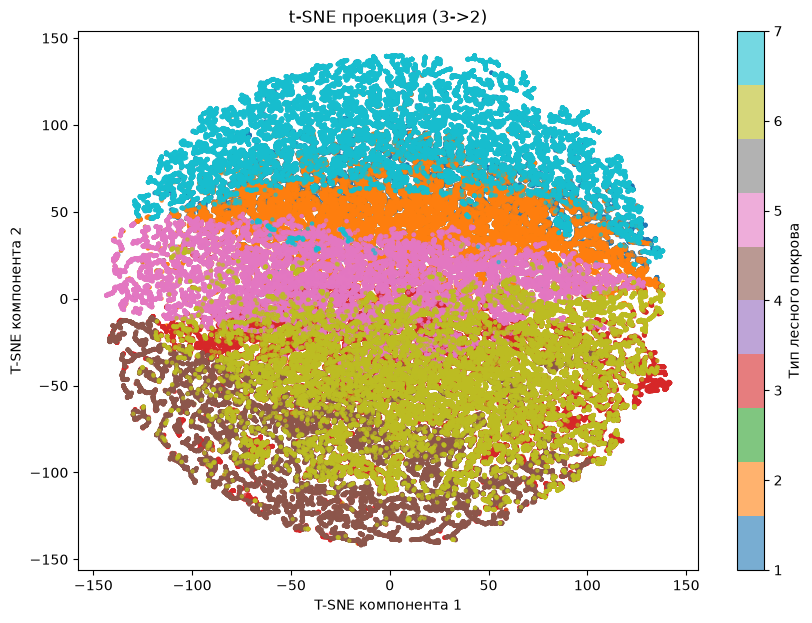

In [70]:
tsne = TSNE(n_components=2, n_jobs=-1)
X_train_tsne_num = tsne.fit_transform(X_train_num)

plt.figure(figsize=(10, 7))
sc = plt.scatter(X_train_tsne_num[:, 0], X_train_tsne_num[:, 1], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(sc, label='Тип лесного покрова')
plt.xlabel('T-SNE компонента 1')
plt.ylabel('T-SNE компонента 2')
plt.title('t-SNE проекция (3->2)')
plt.show()

## Анализ

TSNE применен к сокращенному набору из числовых признаков. Метод использует k ближайших соседей, поэтому точки на графике образуют сферу и являются четко различимыми. Метод не просто развернул пространство, а сформировал распределение внутри ограниченной области. Возможно в трехмерном пространстве данные и так образовывали плотное облако в виде сферы. Алгоритм выполняет нелинейные преобразования, что также могло повлиять на результат.

## Сравнение методов

Сравним четыре результата:

1. Все методы снизили размерность до 2 без учета бинарных данных.
2. По характеру компонент PCA даёт линейные ортогональные комбинации, максимизирующие дисперсию; ICA - линейные комбинации, максимизирующие независимость, без требования ортогональности и без упорядочивания по важности; t-SNE - нелинейное преобразование, сохраняющее локальные соседства.
3. Интерпретируемость выше у PCE и ICE, нежели t-sne
4. По визуальному разделению классов лидирует T-SNE, так как график после применения этого метода имеет самую четкую структуру с явным раздлением на классы, затем PCE за счет слоистой структуры и ICE с самыми нечеткими границами.

Визуальное сходство уже разбиралось.

## Вопросы

1. PCA более предпочтителен в задачах снижения размерности перед обучением модели, когда важна интерпретируемость, скорость обучения и уменьшение количества шумов при условии сохранения большей части полезной информации в виде дисперсии.
2. ICA лучше использовать в задачах разделения сигнала на независимые источники, когда важны сами источники сигнала, а не сжатие данных.

In [84]:
train_A = X_train_pca_A_n90.copy()
train_A['Тип_лесного_покрова'] = y_train.values
test_A = X_test_pca_A_n90.copy()
test_A['Тип_лесного_покрова'] = y_test.values
train_A.to_csv('data/train_pca8.csv', index=False)
test_A.to_csv('data/test_pca8.csv', index=False)
print('A | train_pca8:', train_A.shape, '| NaN:', int(train_A.isna().sum().sum()))
print('A | test_pca8 :', test_A.shape,  '| NaN:', int(test_A.isna().sum().sum()))

train_B = pd.concat([X_train[binary], X_train_pca2_num], axis=1)
train_B['Тип_лесного_покрова'] = y_train.values
test_B = pd.concat([X_test[binary], X_test_pca2_num], axis=1)
test_B['Тип_лесного_покрова'] = y_test.values

train_B.to_csv('data/train_bin44_pca2.csv', index=False)
test_B.to_csv('data/test_bin44_pca2.csv', index=False)

print('B | train_bin44_pca2:', train_B.shape, '| NaN:', int(train_B.isna().sum().sum()))
print('B | test_bin44_pca2 :', test_B.shape,  '| NaN:', int(test_B.isna().sum().sum()))

A | train_pca8: (317254, 9) | NaN: 0
A | test_pca8 : (116194, 9) | NaN: 0
B | train_bin44_pca2: (317254, 47) | NaN: 0
B | test_bin44_pca2 : (116194, 47) | NaN: 0


## Связный текст. Вывод

В ходе лабораторной работы было выполнено снижение размерности датасета Forest Cover Types, причём исследование проводилось для двух случаев: полного набора и только числовых признаков. Метод главных компонент (PCA) и анализ независимых компонент (ICA) занимают важное место на этапе предобработки данных. PCA используется как стандартный инструмент для сжатия признакового пространства перед подачей данных в модель машинного обучения, позволяет избавиться от шума, снизить вычислительную сложность и риск переобучения, сохраняя при этом максимум дисперсии. ICA же применяется в специфических задачах разделения сигналов, когда необходимо выделить независимые источники из смеси.
Для полного набора из 47 признаков методом PCA было выбрано 8 компонент, так как именно на этом шаге накопленная объяснённая дисперсия впервые превышает 90% и составляет 90,55%. Это разумный компромисс между сжатием данных и сохранением информации. Для числового набора достаточно 2 компонент. Метод ICA применялся с 5 компонентами для полного набора и с 2 компонентами для числового для сопоставления с PCA. Применение t-SNE показало, что в 3-х непрерывных признаках скрыта нелинейная структура, однако t-SNE не использовался для конечного датасета для моделирования. Сниженная по размерности выборка сохраняет большую часть исходной дисперсии. Это означает, что она удерживает основные закономерности и корреляции, необходимые для разделения классов. Благодаря сокращению размерности, модель в перспективе будет обучаться быстрее и будет менее склонна к переобучению. Отсутствие пропусков и чёткая структура делают её полностью готовой к дальнейшему использованию в алгоритмах классификации и регрессии.